# BiciMAD infrastructure evolution

This notebook follows how the physical BiciMAD network changed. It starts with the number of bicycles in the network, then the share of their time spent in use, then the number of docks, then the number of bicycles per dock, then the number of stations EMT listed in each status snapshot.


## 0. Setup


In [1]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12

HERE = Path.cwd().resolve()
ROOT = HERE
for _candidate in (HERE, *HERE.parents):
    if (_candidate / "src" / "bicimad" / "__init__.py").is_file():
        ROOT = _candidate
        break
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

from bicimad.config import (
    MADRID_TZ,
    ProjectConfig,
    _month_from_stem,
    discover_months,
    discover_status_files,
    discover_trip_files,
)
from bicimad.download import ensure_status_files, ensure_trip_files
from bicimad.ingest import (
    count_trips_in_progress,
    load_snapshot_station_counts,
    snapshot_dock_capacity,
    snapshot_docked_bikes,
    trip_intervals,
)
from bicimad.utilization import daily_presence_utilization

cfg = ProjectConfig()
print("project root:", cfg.root)


project root: C:\Users\jejoz\Coding\TFG\v1


## 1. Bicycles in the network over time

A bicycle counts as in the network when it is docked at a station or out on a trip. At snapshot time $t$

$$
B(t) = \sum_{s} d_s(t) + \bigl|\{\text{trips in progress at } t\}\bigr|.
$$

Here $d_s(t)$ is `dock_bikes` at station $s$ in the snapshot. The sum covers every listed station, including a station with `no_available` equal to 1. A missing `dock_bikes` counts as zero. A trip is in progress when its start is at or before $t$ and its end is after $t$. A trip with no end time is left out.

The plotted value is the median of $B(t)$ on each calendar day in Europe/Madrid. A day with no snapshot is a gap in the line. The code below downloads any status file or trip file that is not already on disk, then keeps the months present in both archives. Each month is counted on its own, and that month's trips are dropped before the next month is read.


EMT 2017: listing https://media.emtmadrid.es/-HoGTStPZeC


EMT 2017: archive has no station-status files.


EMT 2018: listing https://media.emtmadrid.es/-9iZNUjrjri


EMT 2019: listing https://media.emtmadrid.es/-WNgfSj2ZvC


EMT 2020: listing https://media.emtmadrid.es/-rkuBymuFJX


EMT 2021: listing https://media.emtmadrid.es/-BRk4rTaAdV


... (61 outputs left out)

2022-09: cached, 717 snapshots

2022-10: cached, 739 snapshots

2022-11: cached, 717 snapshots


2022-12: cached, 725 snapshots

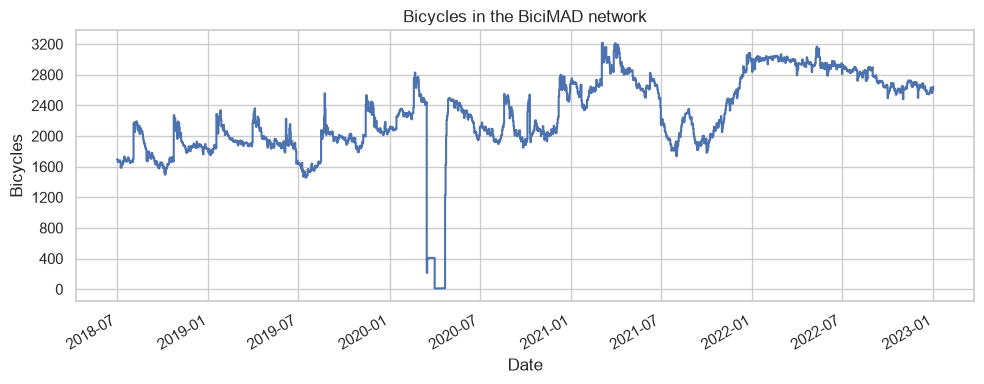

months used: 54 (2018-07 to 2022-12)
months: 2018-07, 2018-08, 2018-09, 2018-10, 2018-11, 2018-12, 2019-01, 2019-02, 2019-03, 2019-04, 2019-05, 2019-06, 2019-07, 2019-08, 2019-09, 2019-10, 2019-11, 2019-12, 2020-01, 2020-02, 2020-03, 2020-04, 2020-05, 2020-06, 2020-07, 2020-08, 2020-09, 2020-10, 2020-11, 2020-12, 2021-01, 2021-02, 2021-03, 2021-04, 2021-05, 2021-06, 2021-07, 2021-08, 2021-09, 2021-10, 2021-11, 2021-12, 2022-01, 2022-02, 2022-03, 2022-04, 2022-05, 2022-06, 2022-07, 2022-08, 2022-09, 2022-10, 2022-11, 2022-12
months inside that span without both files: none
snapshots: 39,252
first day 2018-07-01: 1695.0
last day 2023-01-01: 2643.0
minimum 10.0 on 2020-04-01
maximum 3217.5 on 2021-03-05


In [2]:
import json

status_report = ensure_status_files(cfg)
trip_report = ensure_trip_files(cfg)
print("status files:", status_report["action"].value_counts().to_dict())
print("trip files:", trip_report["action"].value_counts().to_dict())

months = discover_months(cfg)["both"]
if not months:
    raise RuntimeError("No month has both a status file and a trip file.")
status_files = discover_status_files(cfg)
trip_files = discover_trip_files(cfg)
missing_names = [
    path.name
    for path in sorted(cfg.trips_raw.iterdir())
    if path.is_file() and _month_from_stem(path.stem) is None
]
if missing_names:
    raise RuntimeError("Trip files with no month key: " + ", ".join(missing_names))

cache_dir = cfg.processed_dir / "infrastructure" / "bicycle_snapshots"
cache_dir.mkdir(parents=True, exist_ok=True)

frames = []
for month in months:
    status_path = status_files[month]
    trip_path = trip_files[month]
    cache = cache_dir / f"{month}.parquet"
    manifest_path = cache_dir / f"{month}.manifest.json"
    manifest = {
        "status": {"file": status_path.name, "bytes": status_path.stat().st_size},
        "trips": {"file": trip_path.name, "bytes": trip_path.stat().st_size},
    }
    if cache.is_file() and manifest_path.is_file():
        saved = json.loads(manifest_path.read_text(encoding="utf-8"))
        if saved == manifest:
            frame = pd.read_parquet(cache)
            frames.append(frame)
            print(f"{month}: cached, {len(frame):,} snapshots", flush=True)
            continue
    print(f"{month}: counting {status_path.name} and {trip_path.name}", flush=True)
    docked = snapshot_docked_bikes(status_path)
    start_ns, end_ns = trip_intervals(trip_path)
    riding = count_trips_in_progress(
        docked["ts"].astype("int64").to_numpy(),
        start_ns,
        end_ns,
    )
    frame = docked[["ts", "n_docked"]].copy()
    frame["n_riding"] = riding
    frame["n_bikes"] = frame["n_docked"].to_numpy() + riding
    frame["month"] = month
    frame.to_parquet(cache, index=False)
    manifest_path.write_text(json.dumps(manifest), encoding="utf-8")
    print(f"{month}: {len(frame):,} snapshots, {len(start_ns):,} trips", flush=True)
    del docked, start_ns, end_ns, riding
    frames.append(frame)

bikes = pd.concat(frames, ignore_index=True)


def _as_count(series: pd.Series) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce")
    if values.dropna().empty or values.dropna().mod(1).eq(0).all():
        return values.round().astype("Int64")
    return values


local_day = bikes["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D")
bike_daily = (
    bikes.assign(date=local_day)
    .groupby("date", as_index=False)
    .agg(n_bikes=("n_bikes", "median"))
    .sort_values("date")
    .reset_index(drop=True)
)
bike_daily["n_bikes"] = _as_count(bike_daily["n_bikes"])

calendar = pd.date_range(
    bike_daily["date"].min(), bike_daily["date"].max(), freq="D", tz=MADRID_TZ
)
bike_plot = bike_daily.set_index("date").reindex(calendar)

fig, ax = plt.subplots()
ax.step(bike_plot.index.tz_localize(None), bike_plot["n_bikes"], where="post")
ax.set_title("Bicycles in the BiciMAD network")
ax.set_xlabel("Date")
ax.set_ylabel("Bicycles")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

present = bike_plot["n_bikes"].dropna()
span = pd.period_range(months[0], months[-1], freq="M")
inside_missing = [str(period) for period in span if str(period) not in set(months)]
print(f"months used: {len(months)} ({months[0]} to {months[-1]})")
print("months:", ", ".join(months))
print("months inside that span without both files:", inside_missing or "none")
print(f"snapshots: {len(bikes):,}")
print(f"first day {present.index[0].strftime('%Y-%m-%d')}: {present.iloc[0]}")
print(f"last day {present.index[-1].strftime('%Y-%m-%d')}: {present.iloc[-1]}")
print(f"minimum {present.min()} on {present.idxmin().strftime('%Y-%m-%d')}")
print(f"maximum {present.max()} on {present.idxmax().strftime('%Y-%m-%d')}")


The daily median of $B(t)$ starts at 1,695 bicycles on 1 July 2018 and sits close to 2,500 in February 2020. On 16 March 2020 the docked count collapses. From 18 March through 31 March the median stays at 408: about 10 bicycles are still reported in the docks and about 398 are recorded as out on a trip in the March file. From 1 April through 18 April the median is 10, the bicycles still listed in the docks. The count climbs from 22 April and is back near 2,500 at the end of that month.

The highest daily median is 3,217.5 on 5 March 2021. A half bicycle is a day whose snapshots were split between two counts, so the median lies halfway between them. Through 2022 the median stays mostly between 2,600 and 3,000. The last point is 2,643 on 1 January 2023, from the single snapshot at the end of the December 2022 status file.

The series uses the 54 months that have both a status file and a trip file, July 2018 through December 2022. No calendar day from 1 July 2018 through 1 January 2023 is missing a snapshot.


## 2. Bicycle utilization over time

Section 1 counts the bicycles present at each snapshot. This section measures what share of that time is spent in use. On a calendar day $D$ in Europe/Madrid

$$
U(D) = \frac{\int_D R(t)\,dt}{\int_D B(t)\,dt}.
$$

$R(t)$ is the number of trips in progress at time $t$ and $B(t)$ is the fleet from section 1. Between two consecutive snapshots both counts are held at the earlier snapshot. An interval that crosses midnight is split between the two days. A gap longer than 6 hours is left out of both integrals. A day with less than 12 hours of that bracketed time is a gap in the line.

The plotted value is that ratio expressed as a percent. The code reads the snapshot caches written by the bicycle section.


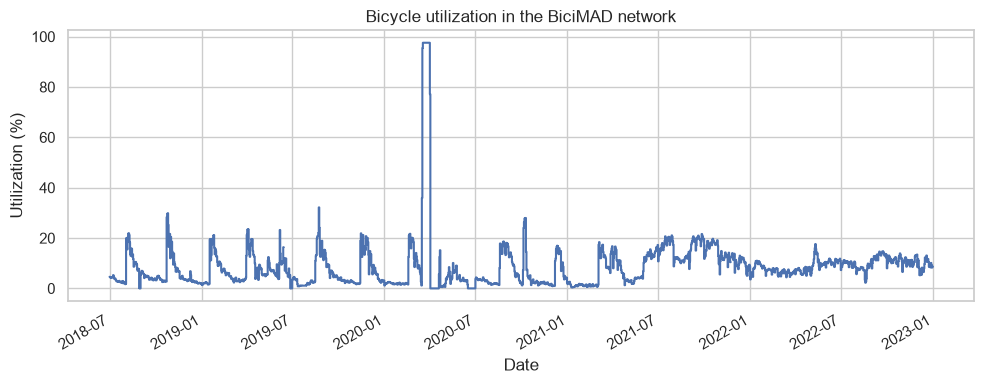

months used: 54 (2018-07 to 2022-12)
months inside that span without both files: none
plotted days: 1,642
gap days: 2019-06-14, 2019-07-09, 2021-11-23, 2023-01-01
first day 2018-07-01: 4.61%
last day 2022-12-31: 8.70%
minimum 0.00% on 2018-08-30
maximum 97.55% on 2020-03-18
median 7.14%
year 2018: median 4.09% over 184 days
year 2019: median 5.33% over 363 days
year 2020: median 3.07% over 366 days
year 2021: median 11.62% over 364 days
year 2022: median 9.17% over 365 days
2020-03-17 to 2020-03-31: 15 days, min 95.42%, max 97.55%
2020-04-01 to 2020-04-01: 1 day, min 77.12%, max 77.12%
2020-04-02 to 2020-04-18: 17 days, min 0.00%, max 0.00%
2018-08-30 to 2018-08-31: 2 days, min 0.00%, max 0.00%
2019-06-27 to 2019-06-30: 4 days, min 0.00%, max 0.06%
2020-06-16 to 2020-06-30: 15 days, min 0.00%, max 0.00%


In [3]:
import json

months = discover_months(cfg)["both"]
if not months:
    raise RuntimeError("No month has both a status file and a trip file.")
status_files = discover_status_files(cfg)
trip_files = discover_trip_files(cfg)
cache_dir = cfg.processed_dir / "infrastructure" / "bicycle_snapshots"

frames = []
for month in months:
    status_path = status_files[month]
    trip_path = trip_files[month]
    cache = cache_dir / f"{month}.parquet"
    manifest_path = cache_dir / f"{month}.manifest.json"
    manifest = {
        "status": {"file": status_path.name, "bytes": status_path.stat().st_size},
        "trips": {"file": trip_path.name, "bytes": trip_path.stat().st_size},
    }
    if not cache.is_file() or not manifest_path.is_file():
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is missing. Run the bicycle section first."
        )
    saved = json.loads(manifest_path.read_text(encoding="utf-8"))
    if saved != manifest:
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is stale. Run the bicycle section first."
        )
    frames.append(pd.read_parquet(cache, columns=["ts", "n_riding", "n_bikes"]))

snapshots = pd.concat(frames, ignore_index=True)
daily = daily_presence_utilization(
    snapshots,
    tz=MADRID_TZ,
    max_gap=pd.Timedelta(hours=6),
)
local_day = snapshots["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D")
calendar = pd.date_range(local_day.min(), local_day.max(), freq="D", tz=MADRID_TZ)
plot = daily.set_index("date").reindex(calendar)
eligible = plot["covered_hours"].ge(12) & plot["present_hours"].gt(0)
rate = plot["utilization"].where(eligible)

fig, ax = plt.subplots()
ax.step(rate.index.tz_localize(None), 100 * rate, where="post")
ax.set_title("Bicycle utilization in the BiciMAD network")
ax.set_xlabel("Date")
ax.set_ylabel("Utilization (%)")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

present = rate.dropna()
pct = 100 * present
gaps = [ts.strftime("%Y-%m-%d") for ts in rate.index[rate.isna()]]
span = pd.period_range(months[0], months[-1], freq="M")
inside_missing = [str(period) for period in span if str(period) not in set(months)]
print(f"months used: {len(months)} ({months[0]} to {months[-1]})")
print("months inside that span without both files:", inside_missing or "none")
print(f"plotted days: {len(present):,}")
print("gap days:", ", ".join(gaps) if gaps else "none")
print(f"first day {present.index[0].strftime('%Y-%m-%d')}: {pct.iloc[0]:.2f}%")
print(f"last day {present.index[-1].strftime('%Y-%m-%d')}: {pct.iloc[-1]:.2f}%")
print(f"minimum {pct.min():.2f}% on {present.idxmin().strftime('%Y-%m-%d')}")
print(f"maximum {pct.max():.2f}% on {present.idxmax().strftime('%Y-%m-%d')}")
print(f"median {pct.median():.2f}%")
for year, group in pct.groupby(pct.index.year):
    print(f"year {year}: median {group.median():.2f}% over {len(group)} days")


def _window(start, end):
    sl = pct.loc[start:end]
    noun = "day" if len(sl) == 1 else "days"
    print(
        f"{start} to {end}: {len(sl)} {noun}, "
        f"min {sl.min():.2f}%, max {sl.max():.2f}%"
    )


_window("2020-03-17", "2020-03-31")
_window("2020-04-01", "2020-04-01")
_window("2020-04-02", "2020-04-18")
_window("2018-08-30", "2018-08-31")
_window("2019-06-27", "2019-06-30")
_window("2020-06-16", "2020-06-30")


The daily value of $U(D)$ starts at 4.61% on 1 July 2018 and the last plotted day is 8.70% on 31 December 2022. The median of the plotted days is 7.14%. The median within each year is 4.09% in 2018, 5.33% in 2019, 3.07% in 2020, 11.62% in 2021, and 9.17% in 2022.

From 17 March through 31 March 2020 the rate stays between 95.42% and 97.55%. The highest day is 97.55% on 18 March 2020. That is the closure already visible in the bicycle count: about 10 bicycles remain in the docks while about 398 trips in the March file stay open, so almost all of the recorded presence is time in use. On 1 April the rate is 77.12%, because the last March snapshot is held across midnight. From 2 April through 18 April the rate is 0.00%.

The minimum is 0.00%, first reached on 30 August 2018. The August 2018 trip file stops on 29 August, and 30–31 August are 0.00% while the docks still report the fleet. The June 2019 file stops on 26 June, and from 27 June through 30 June the rate is at most 0.06%. The June 2020 file covers 1–15 June only, and from 16 June through 30 June the rate is 0.00%. Four days are gaps because less than 12 hours of snapshots are bracketed: 14 June 2019, 9 July 2019, 23 November 2021, and 1 January 2023. The series uses the same 54 months as the bicycle count, July 2018 through December 2022.


## 3. Docks in the network over time

The number of docks at snapshot time $t$ is

$$
C(t) = \sum_s c_s(t).
$$

$c_s(t)$ is `total_bases` at station $s$. The sum covers every listed station, including a station with `no_available` equal to 1. A missing `total_bases` counts as zero.

The plotted value is the median of $C(t)$ on each calendar day in Europe/Madrid. A day with no snapshot is a gap in the line. The code reads the dock totals cached from the status files for July 2018 through December 2022.


2018-07: cached, 744 snapshots


2018-08: cached, 755 snapshots


2018-09: cached, 719 snapshots

2018-10: cached, 745 snapshots


2018-11: cached, 726 snapshots


2018-12: cached, 736 snapshots


... (44 outputs left out)

2022-09: cached, 717 snapshots


2022-10: cached, 739 snapshots


2022-11: cached, 717 snapshots


2022-12: cached, 725 snapshots


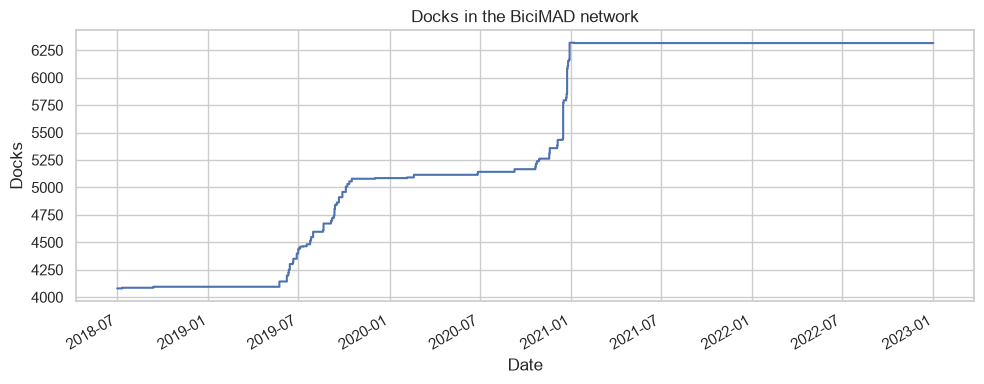

months used: 54 (2018-07 to 2022-12)
months inside that span without a status file: none
snapshots: 39,252
snapshots with no docks: 0
gap days: 0
first day 2018-07-01: 4080.0
last day 2023-01-01: 6315.0
minimum 4080.0 on 2018-07-01
maximum 6318.0 on 2020-12-29


In [2]:
import json

status_files = discover_status_files(cfg)
months = list(status_files)
if not months:
    raise RuntimeError("No status files are on disk.")
dock_dir = cfg.processed_dir / "infrastructure" / "dock_counts"
dock_dir.mkdir(parents=True, exist_ok=True)

frames = []
for month in months:
    status_path = status_files[month]
    dock_cache = dock_dir / f"{month}.parquet"
    dock_manifest_path = dock_dir / f"{month}.manifest.json"
    manifest = {"status": {"file": status_path.name, "bytes": status_path.stat().st_size}}
    docks = None
    if dock_cache.is_file() and dock_manifest_path.is_file():
        saved = json.loads(dock_manifest_path.read_text(encoding="utf-8"))
        if saved == manifest:
            docks = pd.read_parquet(dock_cache)
            print(f"{month}: cached, {len(docks):,} snapshots", flush=True)
    if docks is None:
        print(f"{month}: counting docks in {status_path.name}", flush=True)
        docks = snapshot_dock_capacity(status_path)
        docks.to_parquet(dock_cache, index=False)
        dock_manifest_path.write_text(json.dumps(manifest), encoding="utf-8")
        print(f"{month}: {len(docks):,} snapshots", flush=True)
    frames.append(docks.loc[:, ["ts", "n_docks"]])

snapshots = pd.concat(frames, ignore_index=True)
local_day = snapshots["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D")
daily = (
    snapshots.assign(date=local_day)
    .groupby("date", as_index=False)
    .agg(n_docks=("n_docks", "median"))
    .sort_values("date")
    .reset_index(drop=True)
)


def _as_count(series: pd.Series) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce")
    if values.dropna().empty or values.dropna().mod(1).eq(0).all():
        return values.round().astype("Int64")
    return values


daily["n_docks"] = _as_count(daily["n_docks"])
span_start = snapshots["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D").min()
span_end = snapshots["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D").max()
calendar = pd.date_range(span_start, span_end, freq="D", tz=MADRID_TZ)
plot = daily.set_index("date").reindex(calendar)

fig, ax = plt.subplots()
ax.step(plot.index.tz_localize(None), plot["n_docks"], where="post")
ax.set_title("Docks in the BiciMAD network")
ax.set_xlabel("Date")
ax.set_ylabel("Docks")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

present = plot["n_docks"].dropna()
period_span = pd.period_range(months[0], months[-1], freq="M")
inside_missing = [str(period) for period in period_span if str(period) not in set(months)]
print(f"months used: {len(months)} ({months[0]} to {months[-1]})")
print("months inside that span without a status file:", inside_missing or "none")
print(f"snapshots: {len(snapshots):,}")
print(f"snapshots with no docks: {int((snapshots['n_docks'] == 0).sum()):,}")
print(f"gap days: {int(plot['n_docks'].isna().sum())}")
print(f"first day {present.index[0].strftime('%Y-%m-%d')}: {present.iloc[0]}")
print(f"last day {present.index[-1].strftime('%Y-%m-%d')}: {present.iloc[-1]}")
print(f"minimum {present.min()} on {present.idxmin().strftime('%Y-%m-%d')}")
print(f"maximum {present.max()} on {present.idxmax().strftime('%Y-%m-%d')}")


In [3]:
changed = daily["n_docks"].diff().fillna(0).ne(0)
changed.iloc[0] = True
changes = daily.loc[changed, ["date", "n_docks"]].copy()
changes["change"] = changes["n_docks"].diff()
changes["date"] = changes["date"].dt.strftime("%Y-%m-%d")
changes = changes.rename(columns={"n_docks": "docks"})
with pd.option_context("display.max_rows", None):
    display(changes)


,date,docks,change
0,2018-07-01,4080.0,NaN
10,2018-07-11,4086.0,6.0
73,2018-09-12,4095.0,9.0
327,2019-05-24,4143.0,48.0
342,2019-06-08,4197.0,54.0
345,2019-06-11,4224.0,27.0
346,2019-06-12,4251.0,27.0
348,2019-06-14,4302.0,51.0
354,2019-06-20,4315.5,13.5
355,2019-06-21,4350.0,34.5


The daily median of $C(t)$ starts at 4,080 docks on 1 July 2018 and ends at 6,315 on 1 January 2023. The highest day is 6,318 on 29 December 2020. From 8 January 2021 through 1 January 2023 the median stays at 6,315.

The median steps down twice. On 4 July 2019 it falls from 4,446 to 4,443. On 8 January 2021 it falls from 6,318 to 6,315. On 20 June 2019 the median is 4,315.5. A half dock is a day whose hourly snapshots were split between two counts, so the median lies halfway between them. The table lists every day the median changes.

The series uses the status files from July 2018 through December 2022, the same 54 months as the bicycle count. All 39,252 snapshots have a dock total. No calendar day from 1 July 2018 through 1 January 2023 is missing a snapshot. The point on 1 January 2023 is the single snapshot at the end of the December 2022 status file.


## 4. Bicycles per dock over time

The density of the network at snapshot time $t$ is the fleet from section 1 divided by the number of docks.

$$
\delta(t) = \frac{B(t)}{\sum_s c_s(t)}.
$$

The denominator is the dock count plotted in section 3.

$c_s(t)$ is `total_bases` at station $s$. The sum covers every listed station, including a station with `no_available` equal to 1. A missing `total_bases` counts as zero. A snapshot whose dock total is zero is left out of that day's median.

The plotted value is the median of $\delta(t)$ on each calendar day in Europe/Madrid. A day with no snapshot is a gap in the line. The code reads the bicycle snapshot caches and sums the docks from the status files for the same months.


2018-07: cached, 744 snapshots


2018-08: cached, 755 snapshots


2018-09: cached, 719 snapshots


2018-10: cached, 745 snapshots


2018-11: cached, 726 snapshots


2018-12: cached, 736 snapshots


... (44 outputs left out)

2022-09: cached, 717 snapshots


2022-10: cached, 739 snapshots


2022-11: cached, 717 snapshots


2022-12: cached, 725 snapshots

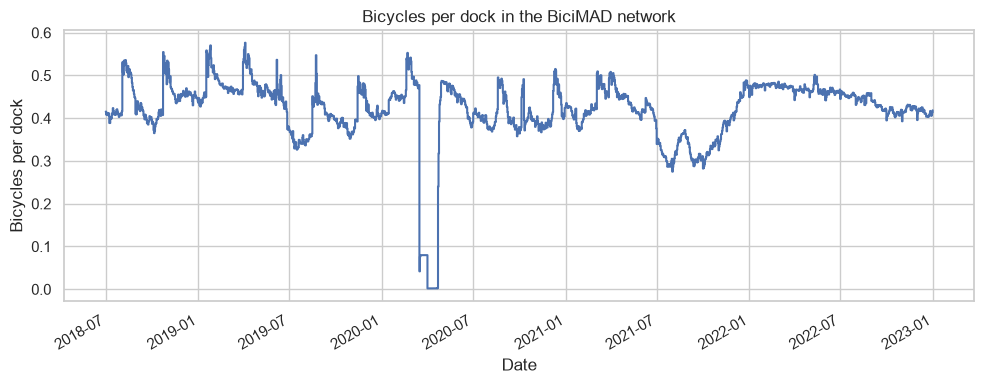

months used: 54 (2018-07 to 2022-12)
months inside that span without both files: none
snapshots: 39,252
snapshots with no docks: 0
gap days: 0
first day 2018-07-01: 0.415
last day 2023-01-01: 0.419
minimum 0.002 on 2020-04-01
maximum 0.577 on 2019-04-04
year 2018: median 0.440 over 184 days
year 2019: median 0.443 over 365 days
year 2020: median 0.411 over 366 days
year 2021: median 0.407 over 365 days
year 2022: median 0.456 over 365 days
year 2023: median 0.419 over 1 days
2020-03-18 to 2020-03-31: 14 days, min 0.080, max 0.080
2020-04-01 to 2020-04-18: 18 days, min 0.002, max 0.002


In [2]:
import json

months = discover_months(cfg)["both"]
if not months:
    raise RuntimeError("No month has both a status file and a trip file.")
status_files = discover_status_files(cfg)
bike_dir = cfg.processed_dir / "infrastructure" / "bicycle_snapshots"
dock_dir = cfg.processed_dir / "infrastructure" / "dock_counts"
dock_dir.mkdir(parents=True, exist_ok=True)

frames = []
for month in months:
    status_path = status_files[month]
    bike_cache = bike_dir / f"{month}.parquet"
    bike_manifest_path = bike_dir / f"{month}.manifest.json"
    if not bike_cache.is_file() or not bike_manifest_path.is_file():
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is missing. Run the bicycle section first."
        )
    saved_bikes = json.loads(bike_manifest_path.read_text(encoding="utf-8"))
    status_manifest = {"file": status_path.name, "bytes": status_path.stat().st_size}
    if saved_bikes.get("status") != status_manifest:
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is stale. Run the bicycle section first."
        )
    bikes = pd.read_parquet(bike_cache, columns=["ts", "n_bikes"])

    dock_cache = dock_dir / f"{month}.parquet"
    dock_manifest_path = dock_dir / f"{month}.manifest.json"
    manifest = {"status": status_manifest}
    docks = None
    if dock_cache.is_file() and dock_manifest_path.is_file():
        saved = json.loads(dock_manifest_path.read_text(encoding="utf-8"))
        if saved == manifest:
            docks = pd.read_parquet(dock_cache)
            print(f"{month}: cached, {len(docks):,} snapshots", flush=True)
    if docks is None:
        print(f"{month}: counting docks in {status_path.name}", flush=True)
        docks = snapshot_dock_capacity(status_path)
        docks.to_parquet(dock_cache, index=False)
        dock_manifest_path.write_text(json.dumps(manifest), encoding="utf-8")
        print(f"{month}: {len(docks):,} snapshots", flush=True)

    merged = bikes.merge(docks, on="ts", how="outer", indicator=True)
    missing = int((merged["_merge"] != "both").sum())
    if missing:
        raise RuntimeError(
            f"{month}: {missing} snapshots are missing from the bicycle cache or the dock count"
        )
    frames.append(merged.loc[:, ["ts", "n_bikes", "n_docks"]])

snapshots = pd.concat(frames, ignore_index=True)
usable = snapshots.loc[snapshots["n_docks"] > 0].copy()
usable["density"] = usable["n_bikes"] / usable["n_docks"]
local_day = usable["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D")
daily = (
    usable.assign(date=local_day)
    .groupby("date", as_index=False)
    .agg(density=("density", "median"))
    .sort_values("date")
    .reset_index(drop=True)
)
span_start = snapshots["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D").min()
span_end = snapshots["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D").max()
calendar = pd.date_range(span_start, span_end, freq="D", tz=MADRID_TZ)
plot = daily.set_index("date").reindex(calendar)

fig, ax = plt.subplots()
ax.step(plot.index.tz_localize(None), plot["density"], where="post")
ax.set_title("Bicycles per dock in the BiciMAD network")
ax.set_xlabel("Date")
ax.set_ylabel("Bicycles per dock")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

present = plot["density"].dropna()
period_span = pd.period_range(months[0], months[-1], freq="M")
inside_missing = [str(period) for period in period_span if str(period) not in set(months)]
print(f"months used: {len(months)} ({months[0]} to {months[-1]})")
print("months inside that span without both files:", inside_missing or "none")
print(f"snapshots: {len(snapshots):,}")
print(f"snapshots with no docks: {int((snapshots['n_docks'] == 0).sum()):,}")
print(f"gap days: {int(plot['density'].isna().sum())}")
print(f"first day {present.index[0].strftime('%Y-%m-%d')}: {present.iloc[0]:.3f}")
print(f"last day {present.index[-1].strftime('%Y-%m-%d')}: {present.iloc[-1]:.3f}")
print(f"minimum {present.min():.3f} on {present.idxmin().strftime('%Y-%m-%d')}")
print(f"maximum {present.max():.3f} on {present.idxmax().strftime('%Y-%m-%d')}")
for year, group in present.groupby(present.index.year):
    print(f"year {year}: median {group.median():.3f} over {len(group)} days")


def _window(start, end):
    sl = present.loc[start:end]
    print(f"{start} to {end}: {len(sl)} days, min {sl.min():.3f}, max {sl.max():.3f}")


_window("2020-03-18", "2020-03-31")
_window("2020-04-01", "2020-04-18")


The daily median of $\delta(t)$ starts at 0.415 bicycles per dock on 1 July 2018. The highest day is 0.577 on 4 April 2019. The median within each year stays between 0.407 and 0.456. The last point is 0.419 on 1 January 2023, from the single snapshot at the end of the December 2022 status file.

From 18 March through 31 March 2020 the median is 0.080. From 1 April through 18 April it is 0.002, and the minimum is 0.002 on 1 April 2020. The docks stay listed while the recorded fleet falls to about 10 bicycles.

The series uses the same 54 months as the bicycle count, July 2018 through December 2022. All 39,252 snapshots have a dock total. No calendar day from 1 July 2018 through 1 January 2023 is missing a snapshot.


## 5. Stations in the network over time

The EMT historical package publishes a snapshot of every station about once an hour. At snapshot time $t$ the size of the network is

$$
N(t) = |\{\text{stations listed in the EMT status snapshot at } t\}|.
$$

A station is active when the snapshot field `activate` equals 1. EMT can keep listing a station that is out of service, so the two counts are kept separate.

The plotted series is the median of each count inside a calendar day in Europe/Madrid. A day with no snapshot is a gap in the line. The download below takes only the station-status members of the 2017–2023 archives. Trip files stay on the server. A file already in `data/raw/status` is left as it is, and the snapshot counts are cached under `data/processed/infrastructure`.


In [4]:
report = ensure_status_files(cfg)
counts = load_snapshot_station_counts(cfg)

months = sorted(counts["month"].unique())
span = pd.period_range(months[0], months[-1], freq="M")
missing = [str(period) for period in span if str(period) not in set(months)]
unpublished = (
    report.loc[report["action"].eq("not published"), "year"].astype(int).tolist()
)
print(f"snapshots: {len(counts):,}")
print(f"status months: {months[0]} to {months[-1]} ({len(months)} months)")
print("months missing inside that span:", missing or "none")
print("yearly archives with no status files:", unpublished)


EMT 2017: listing https://media.emtmadrid.es/-HoGTStPZeC


EMT 2017: archive has no station-status files.


EMT 2018: listing https://media.emtmadrid.es/-9iZNUjrjri


EMT 2019: listing https://media.emtmadrid.es/-WNgfSj2ZvC


EMT 2020: listing https://media.emtmadrid.es/-rkuBymuFJX


EMT 2021: listing https://media.emtmadrid.es/-BRk4rTaAdV


EMT 2022: listing https://media.emtmadrid.es/-uHaW6iZkhG


EMT 2023: listing https://media.emtmadrid.es/-9Nii5DXo4x


EMT 2023: archive has no station-status files.


snapshots: 39,252
status months: 2018-07 to 2022-12 (54 months)
months missing inside that span: none
yearly archives with no status files: [2017, 2023]


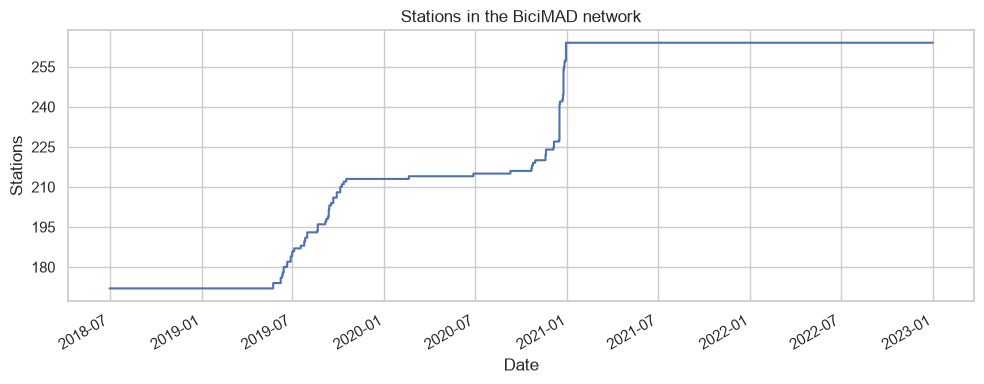

In [5]:
local_day = counts["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D")
daily = (
    counts.assign(date=local_day)
    .groupby("date", as_index=False)
    .agg(n_stations=("n_stations", "median"), n_active=("n_active", "median"))
    .sort_values("date")
    .reset_index(drop=True)
)


def _as_count(series: pd.Series) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce")
    if values.dropna().empty or values.dropna().mod(1).eq(0).all():
        return values.round().astype("Int64")
    return values


daily["n_stations"] = _as_count(daily["n_stations"])
daily["n_active"] = _as_count(daily["n_active"])

calendar = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D", tz=MADRID_TZ)
plot = daily.set_index("date").reindex(calendar)
active_differs = bool(
    (
        plot["n_stations"].notna()
        & plot["n_active"].notna()
        & plot["n_stations"].ne(plot["n_active"])
    ).any()
)

fig, ax = plt.subplots()
x = plot.index.tz_localize(None)
ax.step(x, plot["n_stations"], where="post", label="Listed in the snapshot")
if active_differs:
    ax.step(x, plot["n_active"], where="post", label="Active (activate = 1)")
    ax.legend(frameon=False)
ax.set_title("Stations in the BiciMAD network")
ax.set_xlabel("Date")
ax.set_ylabel("Stations")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [6]:
listed_changed = daily["n_stations"].diff().fillna(0).ne(0)
active_changed = daily["n_active"].diff().fillna(0).ne(0)
presence_changed = daily["n_active"].isna().astype(int).diff().fillna(0).ne(0)
changed = listed_changed | active_changed | presence_changed
changed.iloc[0] = True

changes = daily.loc[changed, ["date", "n_stations", "n_active"]].copy()
changes["change"] = changes["n_stations"].diff()
changes["date"] = changes["date"].dt.strftime("%Y-%m-%d")
changes = changes.rename(columns={"n_stations": "listed", "n_active": "active"})
changes


,date,listed,active,change
0,2018-07-01,172.0,172.0,<NA>
327,2019-05-24,174.0,174.0,2.0
342,2019-06-08,176.0,176.0,2.0
345,2019-06-11,177.0,177.0,1.0
346,2019-06-12,178.0,178.0,1.0
348,2019-06-14,180.0,180.0,2.0
354,2019-06-20,180.5,180.5,0.5
355,2019-06-21,182.0,182.0,1.5
362,2019-06-28,184.0,184.0,2.0
365,2019-07-01,185.5,185.5,1.5


## 6. Reading the series

From 1 July 2018 through 1 January 2023 the daily median rises from 172 stations to 264. Every step in the table is an increase. On every snapshot the active count equals the listed count, so `activate` is 1 for every station in these files.

The median stays at 172 until 24 May 2019. It then rises through the rest of 2019 and reaches 213 on 17 October 2019. The next additions are 214 on 19 February 2020, 215 on 27 June 2020, and 216 on 9 September 2020. From 21 October 2020 to 29 December 2020 the median climbs from 217 to 264. The largest one-day rises are 13.5 stations on 16 December 2020, to 241, then 9.5 on 24 December 2020, to 254, and 6.5 on 29 December 2020, to 264. A half station is a day whose hourly snapshots were split between two counts, so the median lies halfway between them. From 29 December 2020 through 1 January 2023 the median stays at 264. The table lists every day the median changes.

The status files cover every month from July 2018 through December 2022. The 2017 archive and the 2023 archive contain no station-status files, and the 2018 archive begins in July. No calendar day from 1 July 2018 through 1 January 2023 is missing a snapshot. The point on 1 January 2023 is the single snapshot at 00:57 local time at the end of the December 2022 file.
